In [5]:
import os
import numpy as np
import polars as pl
import polars.selectors as cs

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

from hyperopt import fmin, tpe, hp, STATUS_OK, Trials, space_eval

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

if not os.path.exists("datasets"):
    os.mkdir("datasets")

## 1. Carga del dataset completo (lazy, Parquet)

In [7]:
# Buscamos el nombre del archivo parquet del libro
book_file = [f for f in os.listdir("datasets") if "dataset_completo" in f and f.endswith(".parquet")][0]
path_book = os.path.join("datasets", book_file)

# Cargamos como LazyFrame para trabajar de forma eficiente
dataset_completo = pl.scan_parquet(path_book)

In [8]:
# 1. X_features: Todas las columnas MENOS las que empiezan por "label"
X_features = dataset_completo.select(~cs.starts_with("label"))

# 2. y_labels: SOLO las columnas que empiezan por "label"
y_labels = dataset_completo.select(cs.starts_with("label"))

## 2. Ensamblado y limpieza

In [9]:
def finalize_dataset(
    df_features: pl.DataFrame,
    df_labels: pl.DataFrame,
) -> pl.DataFrame:
    """Une features y labels y elimina los nulos generados por ventanas móviles.

    No aplicamos Z-score aquí: la normalización se hará más adelante,
    ajustando el StandardScaler SOLO con datos de entrenamiento de cada
    fold (y, para el modelo final, con todo el pool de CV), evitando así
    fuga de información (data leakage) hacia validación/test.
    """
    full_df = pl.concat([df_features, df_labels], how="horizontal")
    cleaned_df = full_df.drop_nulls()
    return cleaned_df


# Ensamblar y limpiar el dataset final
dataset_final = finalize_dataset(X_features, y_labels)

# Eliminamos columnas que no son features numéricas de entrada al modelo
dataset_final = dataset_final.drop([
    pl.col("mid_price_coordenada"),
    pl.col("^feat_.*$"),  # expresiones regulares nativas de Polars
])



In [10]:
dataset_final.collect().head(10)

v1,v2,v3,v4,v5,v6,v7,v8,v9,v10,v11,v12,v13,v14,v15,v16,v17,v18,v19,v20,v21,v22,v23,v24,v25,v26,v27,v28,v29,v30,v31,v32,v33,v34,v35,v36,v37,…,v113,v114,v115,v116,v117,v118,v119,v120,v121,v122,v123,v124,v125,v126,v127,v128,v129,v130,v131,v132,v133,v134,v135,v136,v137,v138,v139,v140,v141,v142,v143,OBI_Nivel_1,label_k_10,label_k_20,label_k_30,label_k_50,label_k_100
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32,i32,i32,i32,i32
68227.1,3.26,68227.0,6.072,68227.2,0.002,68226.9,0.001,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.0,0.036,0.1,87.754,1.5842e-14,0.1,186.658,5.9720e-12,0.1,636.747,6.4478e-12,0.301329,0,0,0,0,1
68227.1,3.209,68227.0,6.07,68227.2,0.002,68226.9,0.001,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,-0.051,-0.002,0.1,88.292,1.5842e-14,0.1,183.08,5.3311e-12,0.1,636.741,6.2780e-12,0.308331,0,0,0,0,1
68227.1,3.247,68227.0,6.07,68227.2,0.002,68226.9,0.003,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.002,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.038,0.0,0.1,89.45,1.5842e-14,0.1,180.303,4.4790e-12,0.1,638.501,6.0893e-12,0.302995,0,0,0,0,1
68227.1,3.274,68227.0,6.07,68227.2,0.002,68226.9,0.013,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.027,0.0,0.1,92.905,1.5842e-14,0.1,177.553,3.2539e-12,0.1,640.428,5.8799e-12,0.299229,0,0,0,0,1
68227.1,3.418,68227.0,5.968,68227.2,0.002,68226.9,0.013,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.144,-0.102,0.1,93.195,1.5842e-14,0.1,180.917,1.3373e-14,0.1,642.575,5.6474e-12,0.271681,0,0,0,0,1
68227.1,3.418,68227.0,6.004,68227.2,0.005,68226.9,0.013,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.003,0.012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.002,0.0,0.0,0.0,0.036,0.1,93.302,1.5842e-14,0.1,181.311,1.3373e-14,0.1,635.675,5.6474e-12,0.274464,0,0,0,0,1
68227.1,3.418,68227.0,5.465,68227.2,0.005,68226.9,0.013,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.003,0.012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.002,0.0,0.0,0.0,-0.539,0.1,92.87,1.5842e-14,0.1,181.445,1.3373e-14,0.1,628.156,5.6474e-12,0.23044,0,0,0,0,1
68220.1,0.002,68220.0,0.028,68221.2,0.002,68218.7,0.446,68222.3,0.002,68217.9,0.649,68222.7,0.894,68217.1,2.228,68222.8,0.003,68217.0,0.895,68223.1,0.047,68216.9,3.78,68223.5,0.002,68216.8,0.126,68224.4,0.002,68216.7,0.002,68224.7,0.00

## 3. Análisis de correlación con `label_k_100`



In [13]:
dataset_final.collect().corr()

v1,v2,v3,v4,v5,v6,v7,v8,v9,v10,v11,v12,v13,v14,v15,v16,v17,v18,v19,v20,v21,v22,v23,v24,v25,v26,v27,v28,v29,v30,v31,v32,v33,v34,v35,v36,v37,…,v113,v114,v115,v116,v117,v118,v119,v120,v121,v122,v123,v124,v125,v126,v127,v128,v129,v130,v131,v132,v133,v134,v135,v136,v137,v138,v139,v140,v141,v142,v143,OBI_Nivel_1,label_k_10,label_k_20,label_k_30,label_k_50,label_k_100
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
1.0,0.090822,1.0,0.064661,1.0,-0.00133,1.0,0.005403,1.0,0.004214,1.0,0.000358,1.0,0.011429,1.0,-0.003028,1.0,0.015458,1.0,0.003759,1.0,0.000867,0.999999,0.002021,0.999999,0.009293,0.999999,0.002202,0.999999,0.018493,0.999999,0.000139,0.999999,0.006943,0.999999,0.006695,0.999999,…,0.000448,-0.000482,0.000378,-0.000394,0.000442,-0.000371,0.000435,-0.000326,0.000344,-0.000378,0.000274,-0.000331,0.000316,-0.000245,0.000262,-0.000254,0.000244,-0.000252,0.001468,0.001459,0.001109,-0.001101,0.010743,0.147283,0.010487,0.013861,0.152691,0.013989,0.020139,0.166159,0.021178,-0.027116,-0.009052,-0.012741,-0.015052,-0.016994,-0.020542
0.090822,1.0,0.090825,-0.363837,0.0908,0.076498,0.090806,-0.070856,0.090787,0.076787,0.090814,-0.058031,0.090778,0.118817,0.090804,-0.056754,0.09075,0.095524,0.090794,-0.040967,0.090738,0.087446,0.090794,-0.045616,0.090724,0.064042,0.090787,-0.046353,0.090711,0.091637,0.090778,-0.037124,0.090699,0.065079,0.090765,-0.026997,0.090686,…,-0.005037,-0.01948,-0.00763,-0.01623,0.014384,-0.015059,0.013353,-0.012394,0.010202,-0.013467,-0.01095,-0.012276,0.009346,-0.008072,0.009147,-0.009359,0.007531,-0.009273,-0.124074,-0.124535,0.151706,-0.024725,-0.005721,0.569302,-0.005442,-0.005643,0.542263,-0.004924,-0.00465,0.48194,-0.00341,-0.696066,-0.244252,-0.262897,-0.264239,-0.254088,-0.217357
1.0,0.090825,1.0,0.064665,1.0,-0.001335,1.0,0.005394,1.0,0.004208,1.0,0.00035,1.0,0.01142,1.0,-0.003036,1.0,0.015452,1.0,0.003754,0.999999,0.00086,1.0,0.002015,0.999999,0.009288,0.999999,0.002196,0.999999,0.018486,0.999999,0.000133,0.999999,0.006939,0.999999,0.00669,0.999999,…,0.000443,-0.000488,0.000373,-0.000399,0.000435,-0.000376,0.000429,-0.000331,0.000338,-0.000382,0.000269,-0.000336,0.000311,-0.000249,0.000258,-0.000259,0.000239,-0.000257,0.001398,0.001456,0.001117,-0.00109,0.010565,0.147285,0.010308,0.013732,0.152692,0.013857,0.020055,0.16616,0.02109,-0.027116,-0.009053,-0.012742,-0.015053,-0.016995,-0.020543
0.064661,-0.363837,0.064665,1.0,0.064686,-0.060252,0.064682,0.123265,0.064681,-0.061808,0.064694,0.096752,0.064691,-0.090531,0.064707,0.105112,0.0647,-0.072662,0.064732,0.067699,0.064702,-0.07002,0.064752,0.102617,0.064708,-0.046225,0.064764,0.082379,0.064721,-0.068306,0.064775,0.072728,0.064731,-0.047714,0.064786,0.113954,0.064747,…,-0.020225,0.015311,-0.015606,0.003894,-0.020133,-0.006847,-0.017019,0.013002,-0.012675,0.013459,-0.011623,0.0137,-0.012375,-0.000861,-0.011523,0.01184,-0.011059,0.00812,0.138389,0.140837,-0.027157,0.168413,-0.005654,0.460212,-0.004622,-0.005013,0.421962,-0.004129,-0.004638,0.344801,-0.004613,0.719028,0.260974,0.279547,0.281225,0.271918,0.235591
1.0,0.0908,1.0,0.064686,1.0,-0.001327,1.0,0.005415,1.0,0.004219,1.0,0.000369,1.0,0.011437,1.0,-0.003017,1.0,0.015463,0.999999,0.003766,1.0,0.000873,0.999999,0.002029,1.0,0.009296,0.999999,0.00221,0.999999,0.018496,0.999999,0.000144,0.999999,0.006946,0.999999,0.0067,0.999999,…,0.000455,-0.00048,0.000385,-0.000392,0.000449,-0.000368,0.000443,-0.000322,0.000349,-0.000377,0.000278,-0.000329,0.00032,-0.000244,0.000266,-0.000253,0.000248,-0.000251,0.001464,0.001453,0.001103,-0.0011,0.010772,0.147285,0.010513,0.013889,0.152692,0.014015,0.020162,0.166158,0.021199,-0.027086,-0.009038,-0.012726,-0.015038,-0.016981,-0.020531
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,

In [11]:
import polars as pl
import pandas as pd
import numpy as np

TARGET_COL = "label_k_100"
CORR_THRESHOLD = 0.90  # Umbral para eliminar variables redundantes entre sí

# 1. Separar columnas
all_columns = dataset_final.collect_schema().names()
label_cols = [c for c in all_columns if c.startswith("label")]
candidate_feature_cols = [c for c in all_columns if c not in label_cols]

print(f"Calculando matriz de correlación para {len(candidate_feature_cols)} características...")

# 2. Construir expresiones para la matriz de correlación cruzada (todas contra todas)
# Nota: Si tienes miles de columnas, considera aplicar un .head(50000).collect() previo.
matrix_exprs = []
for c1 in candidate_feature_cols:
    for c2 in candidate_feature_cols:
        if c1 >= c2:  # Solo calculamos la mitad para ahorrar tiempo y procesamiento
            matrix_exprs.append(pl.corr(pl.col(c1), pl.col(c2)).alias(f"{c1}__VS__{c2}"))

# Calcular los valores en Polars
corr_results = dataset_final.select(matrix_exprs).collect()

# 3. Reconstruir la matriz simétrica en Pandas para usar sus herramientas de filtrado rápido
corr_matrix_pd = pd.DataFrame(index=candidate_feature_cols, columns=candidate_feature_cols, dtype=float)

for col in corr_results.columns:
    c1, c2 = col.split("__VS__")
    val = corr_results.get_column(col)[0]
    corr_matrix_pd.loc[c1, c2] = val
    corr_matrix_pd.loc[c2, c1] = val

# Llenar la diagonal con 1 por seguridad
np.fill_diagonal(corr_matrix_pd.values, 1.0)
corr_matrix_abs = corr_matrix_pd.abs()

# 4. Encontrar las características redundantes (con correlación > umbral entre ellas)
# Usamos un triángulo superior para no evaluar el mismo par dos veces
upper_tri = corr_matrix_abs.where(np.triu(np.ones(corr_matrix_abs.shape), k=1).astype(bool))

# Identificar qué columnas descartar
cols_to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > CORR_THRESHOLD)]

print(f"\n🔻 Columnas eliminadas por alta correlación ENTRE SÍ (> {CORR_THRESHOLD}) ({len(cols_to_drop)}):")
print(cols_to_drop)

# 5. Crear el nuevo dataset final sin las características redundantes
# Conservamos todas las labels intactas y las features que pasaron el filtro
final_features_to_keep = [c for c in candidate_feature_cols if c not in cols_to_drop]
dataset_filtrado = dataset_final.select(final_features_to_keep + label_cols)


Calculando matriz de correlación para 144 características...

🔻 Columnas eliminadas por alta correlación ENTRE SÍ (> 0.9) (74):
['v3', 'v5', 'v7', 'v9', 'v11', 'v13', 'v15', 'v17', 'v19', 'v21', 'v23', 'v25', 'v27', 'v29', 'v31', 'v33', 'v35', 'v37', 'v39', 'v47', 'v48', 'v49', 'v50', 'v57', 'v58', 'v59', 'v60', 'v67', 'v68', 'v69', 'v70', 'v72', 'v73', 'v74', 'v75', 'v76', 'v77', 'v78', 'v79', 'v80', 'v82', 'v83', 'v84', 'v85', 'v86', 'v87', 'v88', 'v89', 'v90', 'v92', 'v93', 'v94', 'v95', 'v96', 'v97', 'v98', 'v99', 'v100', 'v101', 'v102', 'v103', 'v104', 'v105', 'v106', 'v107', 'v108', 'v109', 'v110', 'v132', 'v137', 'v139', 'v140', 'v142', 'v143']


In [12]:
dataset_final.collect().head(5)

v1,v2,v3,v4,v5,v6,v7,v8,v9,v10,v11,v12,v13,v14,v15,v16,v17,v18,v19,v20,v21,v22,v23,v24,v25,v26,v27,v28,v29,v30,v31,v32,v33,v34,v35,v36,v37,…,v113,v114,v115,v116,v117,v118,v119,v120,v121,v122,v123,v124,v125,v126,v127,v128,v129,v130,v131,v132,v133,v134,v135,v136,v137,v138,v139,v140,v141,v142,v143,OBI_Nivel_1,label_k_10,label_k_20,label_k_30,label_k_50,label_k_100
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32,i32,i32,i32,i32
68227.1,3.26,68227.0,6.072,68227.2,0.002,68226.9,0.001,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.0,0.036,0.1,87.754,1.5842e-14,0.1,186.658,5.9720e-12,0.1,636.747,6.4478e-12,0.301329,0,0,0,0,1
68227.1,3.209,68227.0,6.07,68227.2,0.002,68226.9,0.001,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,-0.051,-0.002,0.1,88.292,1.5842e-14,0.1,183.08,5.3311e-12,0.1,636.741,6.2780e-12,0.308331,0,0,0,0,1
68227.1,3.247,68227.0,6.07,68227.2,0.002,68226.9,0.003,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.002,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.038,0.0,0.1,89.45,1.5842e-14,0.1,180.303,4.4790e-12,0.1,638.501,6.0893e-12,0.302995,0,0,0,0,1
68227.1,3.274,68227.0,6.07,68227.2,0.002,68226.9,0.013,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.027,0.0,0.1,92.905,1.5842e-14,0.1,177.553,3.2539e-12,0.1,640.428,5.8799e-12,0.299229,0,0,0,0,1
68227.1,3.418,68227.0,5.968,68227.2,0.002,68226.9,0.013,68227.8,0.004,68226.6,0.002,68228.4,0.137,68226.4,0.002,68228.5,0.001,68225.7,0.002,68228.6,0.004,68225.5,0.006,68228.9,0.002,68225.4,0.003,68229.0,0.001,68225.3,0.011,68229.2,0.004,68225.2,0.002,68229.3,…,0.0,0.012,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.007,0.0,0.0,0.144,-0.102,0.1,93.195,1.5842e-14,0.1,180.917,1.3373e-14,0.1,642.575,5.6474e-12,0.271681,0,0,0,0,1


## 4. Test ciego final + folds temporales expansivos


In [13]:
all_columns_final = dataset_final.collect_schema().names()
assert TARGET_COL in all_columns_final

df_all = dataset_final.collect()
if "timestamp" in df_all.columns:
    df_all = df_all.sort("timestamp")

total_rows = len(df_all)
test_cutoff = int(total_rows * 0.85)

df_cv_pool = df_all.slice(0, test_cutoff)      # Pool para Cross-Validation + Hyperopt
df_final_test = df_all.slice(test_cutoff)      # Test ciego definitivo

X_final_test_raw = df_final_test.select(final_features_to_keep).to_numpy()
y_final_test = df_final_test.select(TARGET_COL).to_numpy().squeeze().astype(int)

CONFIDENCE_THRESHOLD = 0.55  # umbral usado durante la optimización de hiperparámetros

print(f"CV pool: {df_cv_pool.shape}  |  Test ciego: {df_final_test.shape}")

CV pool: (1184708, 149)  |  Test ciego: (209067, 149)


In [15]:
# ==========================================
# Construcción de folds temporales expansivos
# ==========================================

def stratified_subsample(X, y, max_size, rng):
    if len(y) <= max_size:
        return X, y

    clases, counts = np.unique(y, return_counts=True)
    proportions = counts / counts.sum()
    target_per_class = np.round(proportions * max_size).astype(int)

    idx_parts = []
    for cls, n_take in zip(clases, target_per_class):
        cls_idx = np.where(y == cls)[0]
        n_take = min(n_take, len(cls_idx))  # por si acaso
        chosen = rng.choice(cls_idx, size=n_take, replace=False)
        idx_parts.append(chosen)

    idx = np.concatenate(idx_parts)
    rng.shuffle(idx)
    return X[idx], y[idx]


HYPEROPT_SUBSAMPLE = 500_000  # baja a 50_000 si sigue siendo lento; None para desactivar
rng = np.random.default_rng(42)

N_SPLITS = 4
cv_folds = []
chunk_size = len(df_cv_pool) // (N_SPLITS + 1)
feature_cols = final_features_to_keep

for fold in range(N_SPLITS):
    # Enfoque expansivo: acumulamos el pasado para entrenar
    train_end_idx = chunk_size * (fold + 1)

    train_fold = df_cv_pool.slice(0, train_end_idx)
    val_fold = df_cv_pool.slice(train_end_idx, chunk_size)

    X_tr_raw = train_fold.select(feature_cols).to_numpy()
    y_tr = train_fold.select(TARGET_COL).to_numpy().squeeze().astype(int)

    # 👇 Submuestreo estratificado SOLO para acelerar la búsqueda de hiperparámetros
    # (la validación NO se submuestrea, para que el F1 de comparación sea fiable)
    if HYPEROPT_SUBSAMPLE is not None:
        n_before = len(y_tr)
        X_tr_raw, y_tr = stratified_subsample(X_tr_raw, y_tr, HYPEROPT_SUBSAMPLE, rng)
        if n_before != len(y_tr):
            print(f"Fold {fold}: train submuestreado de {n_before} a {len(y_tr)} filas")

    X_va_raw = val_fold.select(feature_cols).to_numpy()
    y_va = val_fold.select(TARGET_COL).to_numpy().squeeze().astype(int)

    # Escalado: ajustamos el scaler SOLO con el train del fold (ya submuestreado)
    fold_scaler = StandardScaler()
    X_tr = fold_scaler.fit_transform(X_tr_raw)
    X_va = fold_scaler.transform(X_va_raw)

    # Pesos por clase específicos de este fold (desbalanceo)
    clases_fold = np.unique(y_tr)
    pesos_fold = compute_class_weight(class_weight="balanced", classes=clases_fold, y=y_tr)
    class_weight_fold = dict(zip(clases_fold, pesos_fold))

    cv_folds.append((X_tr, y_tr, X_va, y_va, class_weight_fold))

print(f"✅ {len(cv_folds)} folds temporales construidos (tamaño de cada bloque ≈ {chunk_size} filas).")

Fold 2: train submuestreado de 710823 a 500000 filas
Fold 3: train submuestreado de 947764 a 500001 filas
✅ 4 folds temporales construidos (tamaño de cada bloque ≈ 236941 filas).


## 5. Espacio de búsqueda de Hyperopt

Optimizamos los hiperparámetros más relevantes de `LogisticRegression`:
- `C`: inverso de la regularización (a menor `C`, más regularización).
- `penalty`: `l1`, `l2` o `elasticnet`.
- `l1_ratio`: solo se usa cuando `penalty="elasticnet"`.

Usamos `solver="saga"`, que es el único solver de scikit-learn que soporta `l1`, `l2` y `elasticnet` en el caso multinomial.

In [16]:
space = {
    "C": hp.loguniform("C", np.log(1e-3), np.log(1e2)),
    "penalty": hp.choice("penalty", ["l1", "l2", "elasticnet"]),
    "l1_ratio": hp.uniform("l1_ratio", 0.0, 1.0),
    "tol": hp.loguniform("tol", np.log(1e-3), np.log(1e-1)),
}

## 6. Función objetivo con validación cruzada temporal

In [17]:
def build_logreg(params):
    penalty = params["penalty"]
    kwargs = dict(
        solver="saga",
        multi_class="multinomial",
        max_iter=3000,
        C=params["C"],
        tol=params["tol"],
        penalty=penalty,
        n_jobs=-1,
    )
    if penalty == "elasticnet":
        kwargs["l1_ratio"] = params["l1_ratio"]
    return kwargs


def objective(params):
    f1_scores_folds = []

    for X_tr, y_tr, X_va, y_va, class_weight_fold in cv_folds:
        model_kwargs = build_logreg(params)
        model = LogisticRegression(class_weight=class_weight_fold, **model_kwargs)
        model.fit(X_tr, y_tr)

        preds_prob = model.predict_proba(X_va)

        y_pred_tmp = np.ones(len(preds_prob), dtype=int)  # por defecto: STAT
        y_pred_tmp[preds_prob[:, 0] >= CONFIDENCE_THRESHOLD] = 0
        y_pred_tmp[preds_prob[:, 2] >= CONFIDENCE_THRESHOLD] = 2

        f1_fold = f1_score(y_va, y_pred_tmp, labels=[0, 2], average="macro", zero_division=0)
        f1_scores_folds.append(f1_fold)

    mean_f1 = float(np.mean(f1_scores_folds))

    return {"loss": -mean_f1, "status": STATUS_OK, "mean_f1": mean_f1}

## 7. Ejecutar la búsqueda de hiperparámetros

In [18]:
MAX_EVALS = 20

trials = Trials()

best_raw = fmin(
    fn=objective,
    space=space,
    algo=tpe.suggest,
    max_evals=MAX_EVALS,
    trials=trials,
    rstate=np.random.default_rng(42),
)

best_params = space_eval(space, best_raw)
best_mean_f1 = -min(trials.losses())

print("🏆 Mejores hiperparámetros encontrados:")
print(best_params)
print(f"\nF1-macro (DOWN/UP) promedio en CV con estos hiperparámetros: {best_mean_f1:.4f}")

  0%|          | 0/20 [00:00<?, ?trial/s, best loss=?]

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and

  5%|▌         | 1/20 [00:26<08:32, 26.95s/trial, best loss: -0.26050046081700595]

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and

 10%|█         | 2/20 [01:59<19:34, 65.25s/trial, best loss: -0.2768770864976166] 

...

 90%|█████████ | 18/20 [24:09<02:37, 78.71s/trial, best loss: -0.28076676703281206]

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and

 95%|█████████▌| 19/20 [26:20<01:34, 94.35s/trial, best loss: -0.28076676703281206]

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and

100%|██████████| 20/20 [27:34<00:00, 82.71s/trial, best loss: -0.28076676703281206]
🏆 Mejores hiperparámetros encontrados:
{'C': 59.415838911164116, 'l1_ratio': 0.26832475371053754, 'penalty': 'l2', 'tol': 0.00117329405925892}

F1-macro (DOWN/UP) promedio en CV con estos hiperparámetros: 0.2808


## 8. Entrenamiento del modelo final

Con los mejores hiperparámetros, reentrenamos sobre **todo** el pool de CV (85%), ajustando un único `StandardScaler` sobre ese mismo pool (y aplicándolo también al test ciego, sin volver a ajustarlo).

In [19]:
X_cv_pool_raw = df_cv_pool.select(feature_cols).to_numpy()
y_cv_pool = df_cv_pool.select(TARGET_COL).to_numpy().squeeze().astype(int)

scaler = StandardScaler()
X_cv_pool = scaler.fit_transform(X_cv_pool_raw)
X_final_test = scaler.transform(X_final_test_raw)

clases_final = np.unique(y_cv_pool)
pesos_final = compute_class_weight(class_weight="balanced", classes=clases_final, y=y_cv_pool)
class_weight_final = dict(zip(clases_final, pesos_final))

final_model_kwargs = build_logreg(best_params)
modelo_final = LogisticRegression(class_weight=class_weight_final, **final_model_kwargs)
modelo_final.fit(X_cv_pool, y_cv_pool)

print("✅ Modelo final de Regresión Logística entrenado con los mejores hiperparámetros de Hyperopt.")

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


✅ Modelo final de Regresión Logística entrenado con los mejores hiperparámetros de Hyperopt.


## 9. Evaluación estándar sobre el test ciego (predicción por defecto, `argmax`)

📊 REPORT DE CLASIFICACIÓN — REGRESIÓN LOGÍSTICA (predicción estándar, TEST CIEGO)
                precision    recall  f1-score   support

DOWN (Clase 0)     0.4590    0.5406    0.4965     58480
STAT (Clase 1)     0.5178    0.3052    0.3841     89576
  UP (Clase 2)     0.4434    0.6351    0.5222     61011

      accuracy                         0.4673    209067
     macro avg     0.4734    0.4937    0.4676    209067
  weighted avg     0.4796    0.4673    0.4558    209067



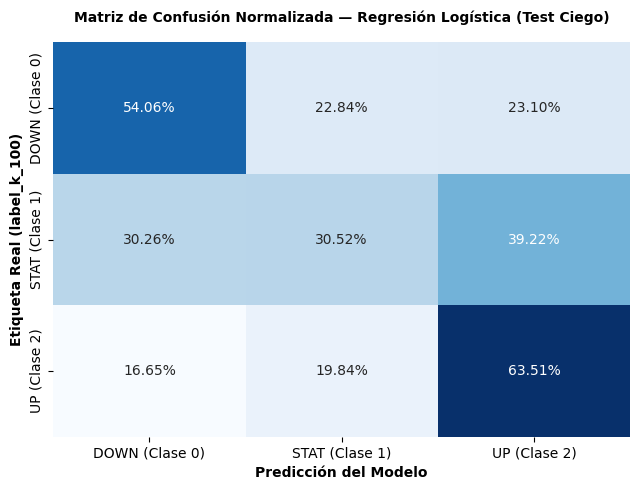

In [20]:
y_pred_default = modelo_final.predict(X_final_test)
nombres_clases = ['DOWN (Clase 0)', 'STAT (Clase 1)', 'UP (Clase 2)']

print("="*70)
print("📊 REPORT DE CLASIFICACIÓN — REGRESIÓN LOGÍSTICA (predicción estándar, TEST CIEGO)")
print("="*70)
print(classification_report(
    y_final_test,
    y_pred_default,
    target_names=nombres_clases,
    zero_division=0,
    digits=4
))

cm = confusion_matrix(y_final_test, y_pred_default, normalize='true')
plt.figure(figsize=(6.5, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=nombres_clases,
    yticklabels=nombres_clases,
    cbar=False
)
plt.title('Matriz de Confusión Normalizada — Regresión Logística (Test Ciego)', fontsize=10, fontweight='bold', pad=15)
plt.ylabel('Etiqueta Real (label_k_100)', fontweight='bold')
plt.xlabel('Predicción del Modelo', fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Evaluación con umbral de confianza sobre el test ciego



In [21]:
probs = modelo_final.predict_proba(X_final_test)
prob_down = probs[:, 0]
prob_stat = probs[:, 1]
prob_up   = probs[:, 2]

thresholds = [0.3333, 0.50, 0.55, 0.60, 0.65, 0.70]

for ts in thresholds:
    y_pred_custom = np.ones(len(probs), dtype=int)  # por defecto: STAT
    y_pred_custom[prob_down >= ts] = 0
    y_pred_custom[prob_up >= ts] = 2

    print("="*70)
    print(f"📊 REPORT CIENTÍFICO REGRESIÓN LOGÍSTICA - UMBRAL DEL {int(ts*100)}% (TEST CIEGO)")
    print("="*70)
    print(classification_report(
        y_final_test,
        y_pred_custom,
        target_names=nombres_clases,
        zero_division=0,
        digits=4
    ))

    cm_custom = confusion_matrix(y_final_test, y_pred_custom)
    print("Matriz de Confusión:")
    print(f"                Pred: DOWN   Pred: STAT   Pred: UP")
    for i, real_name in enumerate(["DOWN", "STAT", "UP"]):
        print(f"Real: {real_name:<9}" + "".join(f"{v:<13}" for v in cm_custom[i]))

    total_trades = np.sum((y_pred_custom == 0) | (y_pred_custom == 2))
    pct_operado = (total_trades / len(y_final_test)) * 100
    print(f"📈 Grado de actividad en mercado: {pct_operado:.2f}% de los ticks operados.\n")

📊 REPORT CIENTÍFICO REGRESIÓN LOGÍSTICA - UMBRAL DEL 33% (TEST CIEGO)
                precision    recall  f1-score   support

DOWN (Clase 0)     0.4215    0.6285    0.5046     58480
STAT (Clase 1)     0.5114    0.1074    0.1775     89576
  UP (Clase 2)     0.4205    0.7102    0.5282     61011

      accuracy                         0.4291    209067
     macro avg     0.4511    0.4821    0.4035    209067
  weighted avg     0.4597    0.4291    0.3714    209067

Matriz de Confusión:
                Pred: DOWN   Pred: STAT   Pred: UP
Real: DOWN     36757        4850         16873        
Real: STAT     37110        9622         42844        
Real: UP       13338        4342         43331        
📈 Grado de actividad en mercado: 91.00% de los ticks operados.

📊 REPORT CIENTÍFICO REGRESIÓN LOGÍSTICA - UMBRAL DEL 50% (TEST CIEGO)
                precision    recall  f1-score   support

DOWN (Clase 0)     0.6085    0.2035    0.3050     58480
STAT (Clase 1)     0.4721    0.8285    0.6015     8

## 11. Guardar modelo, scaler e hiperparámetros

In [22]:
import json as _json

joblib.dump(modelo_final, "final_model_logreg.joblib")
joblib.dump(scaler, "final_scaler_logreg.joblib")

with open("final_model_logreg_best_params.json", "w") as f:
    _json.dump(best_params, f, indent=2)

print("💾 Modelo, StandardScaler e hiperparámetros óptimos guardados correctamente.")

💾 Modelo, StandardScaler e hiperparámetros óptimos guardados correctamente.
